In [319]:
import pandas as pd
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

In [320]:
centroids = [(-5,-5),(5,5),(-2.5,2.5),(5,-4)]
cluster_std = [1,1,1,1]

X,y = make_blobs(n_samples=200, cluster_std=cluster_std, centers=centroids, n_features=2, random_state=28)


In [321]:
X = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/student_clustering.csv')

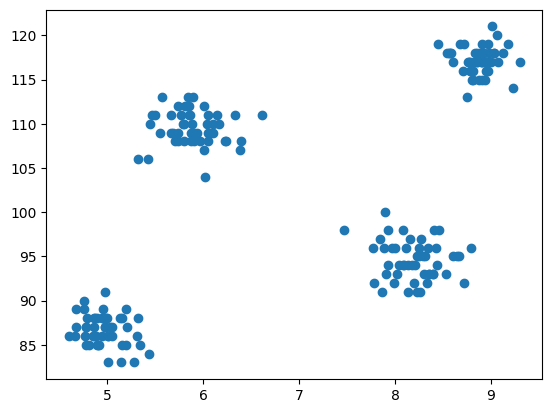

In [322]:
plt.scatter(X['cgpa'],X['iq'])

In [323]:
import random
import numpy as np

In [324]:
class KMeans:
    def __init__(self,n_clusters=2,max_iter=300):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.centroids = None

    def fit_predict(self,X):
        random_indx = random.sample(range(0,X.shape[0]),self.n_clusters)
        self.centroids = X[random_indx]

        for i in range(self.max_iter):
            cluster_group = self.assign_cluster(X)

            old_centroids = self.centroids
            self.centroids = self.move_centroids(X,cluster_group)

            if (old_centroids == self.centroids).all():
                break

        return cluster_group




    def assign_cluster(self,X):
        cluster_group = []

        for row in X:
            distances = []
            for centroid in self.centroids:
                distances.append(np.sqrt(np.dot(centroid-row,centroid-row)))

            cluster_group.append(distances.index(min(distances)))
        return np.array(cluster_group)
    
    def move_centroids(self,X,cluster_group):
        new_centroids = []

        cluster_type = np.unique(cluster_group)

        for type in cluster_type:
            new_centroids.append(X[cluster_group == type].mean(axis=0))
        
        return np.array(new_centroids)



In [325]:
km = KMeans(n_clusters=4)
y_pred = km.fit_predict(X.values)

In [326]:
km.centroids

array([[  4.9676,  86.7   ],
       [  8.1998,  94.6   ],
       [  5.8948, 109.52  ],
       [  8.8714, 117.16  ]])

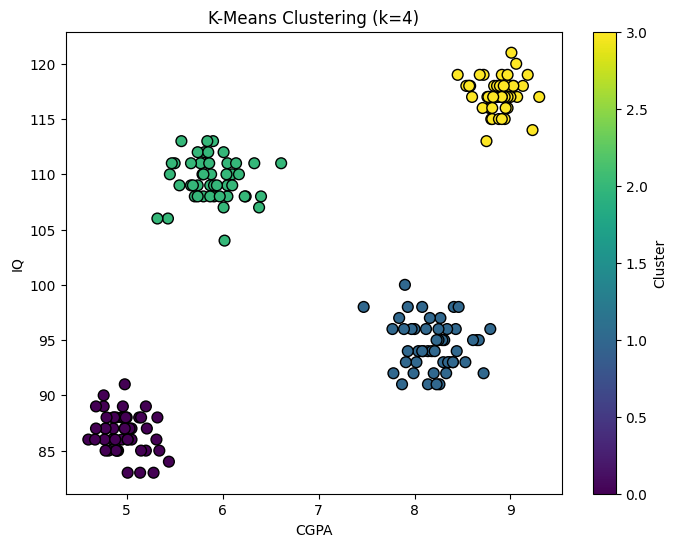

In [327]:
# Plot the clustered data points with their cluster assignments
plt.figure(figsize=(8,6))
plt.scatter(X['cgpa'], X['iq'], c=y_pred, cmap='viridis', edgecolor='k', s=60)
plt.xlabel('CGPA')
plt.ylabel('IQ')
plt.title('K-Means Clustering (k=4)')
plt.colorbar(label='Cluster')
plt.show()